# The Kalman Filter

---

The Kalman Filter is an optimal estimation algorithm that infers the hidden state of a linear dynamic system from a series of noisy measurements. 
It plays a crucial role in control theory, navigation, and time-series analysis in quantitative finance — allowing us to smooth out noise, estimate hidden variables, and adapt to changing market conditions dynamically.

## 1. Historical Background

### 1.1 The Apollo Program (Rudolf E. Kálmán, 1960)

The story of the Kalman filter begins with **Rudolf E. Kálmán**, a Hungarian-American mathematician who published his seminal paper in 1960. 

The engineering problem at the time was monumental: **How do we accurately track and predict the trajectory of a spacecraft heading to the moon when our sensors are inherently noisy and imprecise?**

Kálmán devised a recursive mathematical algorithm that could efficiently estimate the true state of a linear system (like a rocket's position and velocity) from a series of imperfect measurements. This algorithm became a cornerstone of the navigation systems for the **Apollo space program**, allowing the command module to determine its precise location in space.

### 1.2 From Engineering to Finance

While originally designed for aerospace and robotics, the Kalman Filter's ability to extract signals from noise makes it incredibly powerful in finance.

- **Dynamic Hedge Ratios** — Unlike static linear regression (OLS), the Kalman Filter can continuously update the co-integration coefficient (hedge ratio) between two assets in a Pairs Trading strategy.
- **Hidden Markov Models (HMMs)** — It serves as a continuous-state counterpart to HMMs, estimating the hidden "true price" or "true volatility" from observed noisy trades.
- **Adaptive Moving Averages** — It provides a highly responsive, zero-lag smoothing mechanism for price data.

### 1.3 Modern Usage

| Domain | Application |
|--------|-------------|
| **Aerospace & Robotics** | Radar tracking, GPS navigation, self-driving cars |
| **Quantitative Finance** | Pairs trading, algorithmic execution, volatility estimation |
| **Macroeconomics** | Estimating unobservable variables like the output gap or NAIRU |
| **Signal Processing** | Speech enhancement, noise reduction |

## 2. State-Space Models

To understand the Kalman Filter, we must first understand the **State-Space formulation**.

A state-space model assumes that there is a **hidden true state** of a system that we cannot observe directly. Instead, we can only observe **noisy measurements** of that state.

The system is defined by two main equations:

### 2.1 The State Equation (Dynamics)

The hidden true state $x_k$ at time $k$ evolves from the previous state $x_{k-1}$ according to:

$$ x_k = F_k x_{k-1} + B_k u_k + w_k $$

- $x_k$: The hidden state vector (e.g., true position and velocity).
- $F_k$: The state transition matrix (how the state evolves organically).
- $B_k u_k$: Control input (external forces applied to the system).
- $w_k$: Process noise (inherent uncertainty in the system's evolution), assumed to be drawn from a multivariate normal distribution with covariance $Q_k$ ($w_k \sim \mathcal{N}(0, Q_k)$).

### 2.2 The Observation Equation (Measurements)

The actual noisy measurement $z_k$ we observe at time $k$ is related to the true state $x_k$ by:

$$ z_k = H_k x_k + v_k $$

- $z_k$: The observation vector (e.g., GPS sensor reading, or observed stock price).
- $H_k$: The observation matrix (maps the true state space into the observed space).
- $v_k$: Measurement noise (sensor inaccuracy or market microstructure noise), assumed to be drawn from a multivariate normal distribution with covariance $R_k$ ($v_k \sim \mathcal{N}(0, R_k)$).

### 2.3 The Goal of the Kalman Filter

The Kalman Filter's goal is to compute the **optimal estimate** of the hidden state $x_k$, denoted as $\hat{x}_k$, by minimizing the mean squared error of the estimate, balancing the dynamic prediction against the noisy measurement.

## 3. The Predict and Update Cycle

The algorithm runs recursively in two distinct steps: **Predict** (Time Update) and **Update** (Measurement Correct).

### Step 1: Predict (Prior Estimate)

Before we take a new measurement, we project the current state estimate forward in time.

1. **State Prediction:**
   $$ \hat{x}_{k|k-1} = F_k \hat{x}_{k-1|k-1} + B_k u_k $$
   *(Where do we think we are based solely on our dynamic model?)*

2. **Error Covariance Prediction:**
   $$ P_{k|k-1} = F_k P_{k-1|k-1} F_k^T + Q_k $$
   *(How uncertain are we about this prediction? Process noise $Q_k$ increases our uncertainty.)*

### Step 2: Update (Posterior Estimate)

When we receive a new noisy observation $z_k$, we update our prediction.

3. **Innovation (Measurement Residual):**
   $$ y_k = z_k - H_k \hat{x}_{k|k-1} $$
   *(What is the difference between what we observed and what we predicted?)*

4. **Innovation Covariance:**
   $$ S_k = H_k P_{k|k-1} H_k^T + R_k $$
   *(How much uncertainty is in this residual? Measurement noise $R_k$ adds to it.)*

5. **Kalman Gain:**
   $$ K_k = P_{k|k-1} H_k^T S_k^{-1} $$
   *(How much should we trust the measurement vs. our dynamic prediction? High $R_k \rightarrow$ low $K_k$ (trust prediction). High $P_{k|k-1} \rightarrow$ high $K_k$ (trust measurement).)*

6. **State Update:**
   $$ \hat{x}_{k|k} = \hat{x}_{k|k-1} + K_k y_k $$
   *(Update the state estimate by blending the prediction and the residual using the Kalman Gain.)*

7. **Error Covariance Update:**
   $$ P_{k|k} = (I - K_k H_k) P_{k|k-1} $$
   *(Update the uncertainty. Receiving a measurement generally decreases our uncertainty.)*

---

# Part II — Code: 1D Kalman Filter Implementation

1. **Setup**: Import necessary libraries.
2. **Data Generation**: Create a synthetic 1D tracking scenario (e.g., a car moving at a constant velocity but observed via a noisy GPS).
3. **The Filter**: Implement the Kalman Filter mathematically from scratch.
4. **Visualization**: Plot the True State, the Noisy Observations, and our Kalman Estimate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (14, 6),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
})

# For reproducibility
np.random.seed(42)
print('Setup complete')

Setup complete


## 4. Generating Synthetic Data (1D Tracking)

Let's simulate a vehicle moving in 1D space ($x$ coordinate) with a true, constant velocity. Our sensor (e.g., a GPS) takes readings of the vehicle's position every second, but these readings are strictly noisy.

- **True State**: Evolving linearly based on velocity.
- **Observations**: True State + Gaussian Noise.

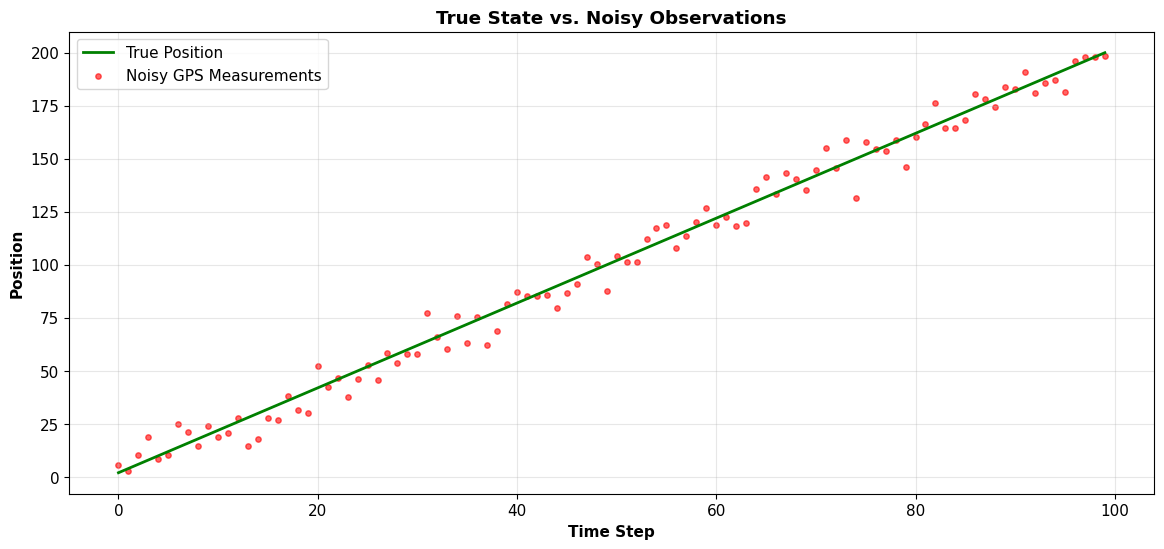

In [2]:
n_steps = 100
dt = 1.0  # Time step

# True initial state
true_position = 0.0
true_velocity = 2.0

true_states = []
measurements = []

# Measurement noise variance (R)
measurement_noise_variance = 50.0

current_pos = true_position
for _ in range(n_steps):
    # Evolve the true state
    current_pos += true_velocity * dt
    true_states.append(current_pos)
    
    # Observe the noisy measurement
    noise = np.random.normal(0, np.sqrt(measurement_noise_variance))
    measurements.append(current_pos + noise)

true_states = np.array(true_states)
measurements = np.array(measurements)

# Let's visualize the raw noisy measurements vs. the true state
plt.plot(true_states, label='True Position', color='green', linewidth=2)
plt.scatter(range(n_steps), measurements, label='Noisy GPS Measurements', color='red', alpha=0.6, s=15)
plt.title('True State vs. Noisy Observations')
plt.xlabel('Time Step')
plt.ylabel('Position')
plt.legend()
plt.show()

## 5. Implementing the 1D Kalman Filter

Now we configure the matrices for our state equations.

We are tracking a state vector $x = [\text{position}, \text{velocity}]^T$.

**State Transition Matrix ($F$):**
$$ x_{k} = \begin{bmatrix} 1 & dt \\ 0 & 1 \end{bmatrix} \begin{bmatrix} \text{pos}_{k-1} \\ \text{vel}_{k-1} \end{bmatrix} + w_k $$

**Observation Matrix ($H$):**
We only observe the position, not the velocity.
$$ z_k = \begin{bmatrix} 1 & 0 \end{bmatrix} x_k + v_k $$

We will step through the `Predict` and `Update` cycle for each measurement.

In [3]:
# --- Initialization ---

# Define the state vector estimate: [position, velocity]
# We make an initial guess (which might be totally wrong!).
x_est = np.array([[0.0], [0.0]]) 

# Define the State Transition Matrix (F)
F = np.array([[1.0, dt], 
              [0.0, 1.0]])

# Define the Observation Matrix (H) - we only observe position
H = np.array([[1.0, 0.0]])

# Define Initial Uncertainty / Covariance Matrix (P)
# High values signify we don't trust our initial guess x_est
P = np.array([[1000.0, 0.0],
              [0.0, 1000.0]])

# Measurement Noise Covariance (R) - directly related to sensor variance
R = np.array([[measurement_noise_variance]])

# Process Noise Covariance (Q) - small value assuming our constant velocity model is quite good
Q = np.array([[1.0, 0.0],
              [0.0, 1.0]]) * 0.1  # small arbitrary variance

# To store the estimates for plotting
kalman_estimates = []

# --- The Filter Loop ---
for z in measurements:
    # -----------------------------
    # STEP 1: PREDICT (Time Update)
    # -----------------------------
    # Predict the next state
    x_pred = F @ x_est
    
    # Predict the next error covariance
    P_pred = F @ P @ F.T + Q
    
    # -----------------------------
    # STEP 2: UPDATE (Measurement Correct)
    # -----------------------------
    # Compute Observation Residual (Innovation)
    y = np.array([[z]]) - H @ x_pred
    
    # Compute the Innovation Covariance
    S = H @ P_pred @ H.T + R
    
    # Compute the Kalman Gain
    K = P_pred @ H.T @ np.linalg.inv(S)
    
    # Update the State Estimate
    x_est = x_pred + K @ y
    
    # Update the Error Covariance
    # Identity matrix matching the size of State Matrix
    I = np.eye(F.shape[0])
    P = (I - K @ H) @ P_pred
    
    # Store the estimated position
    kalman_estimates.append(x_est[0, 0])

kalman_estimates = np.array(kalman_estimates)

print("Kalman Filter execution complete.")

Kalman Filter execution complete.


## 6. Visualizing the Filter's Performance

Let's overlay our Kalman Filter's position estimate onto the true position and the original noisy measurements. Notice how effectively the algorithm dismisses the noise while perfectly adapting to the dynamic true state!

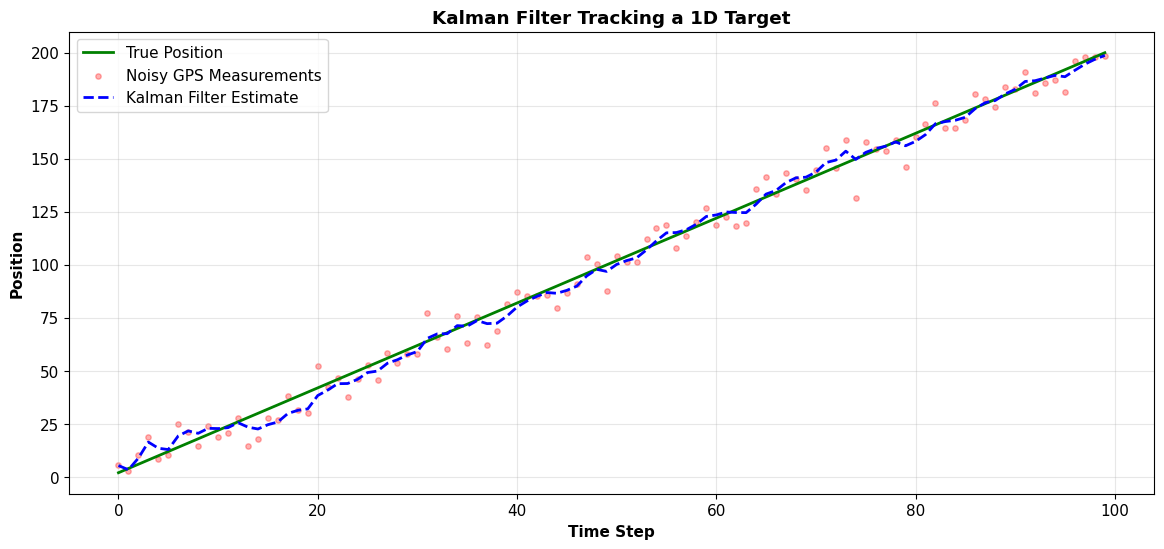

In [4]:
plt.plot(true_states, label='True Position', color='green', linewidth=2)
plt.scatter(range(n_steps), measurements, label='Noisy GPS Measurements', color='red', alpha=0.3, s=15)
plt.plot(kalman_estimates, label='Kalman Filter Estimate', color='blue', linewidth=2, linestyle='--')

plt.title('Kalman Filter Tracking a 1D Target')
plt.xlabel('Time Step')
plt.ylabel('Position')
plt.legend()
plt.show()

---
# Part III — Financial Application: Dynamic Hedge Ratios

In algorithmic trading (especially **Pairs Trading**), we often look for two assets (Let's say $X$ and $Y$) that are cointegrated. The standard approach is to run a static Ordinary Least Squares (OLS) regression:
$$ Y_t = \beta X_t + \alpha + \epsilon_t $$
Where $\beta$ is the hedge ratio. 

**The Flaw with Static OLS**
Financial markets are non-stationary. A static hedge ratio calculated over the last 100 days might be completely wrong today. If the relationship between $X$ and $Y$ changes, our static hedge ratio will cause us to hold incorrect position sizes.

**The Kalman Filter Solution**
We can use the Kalman Filter to continuously update our estimate of the hedge ratio $\beta_t$ and the intercept $\alpha_t$ at every time step! 

Here, our **hidden state** is $\theta_t = [\beta_t, \alpha_t]^T$.
Our **observation** is simply the price of $Y_t$, and the observation matrix $H_t$ is $[X_t, 1]$.

Let's simulate a scenario where the true hedge ratio between two assets slowly drifts over time, and see how the Kalman Filter tracks it compared to a static OLS regression.

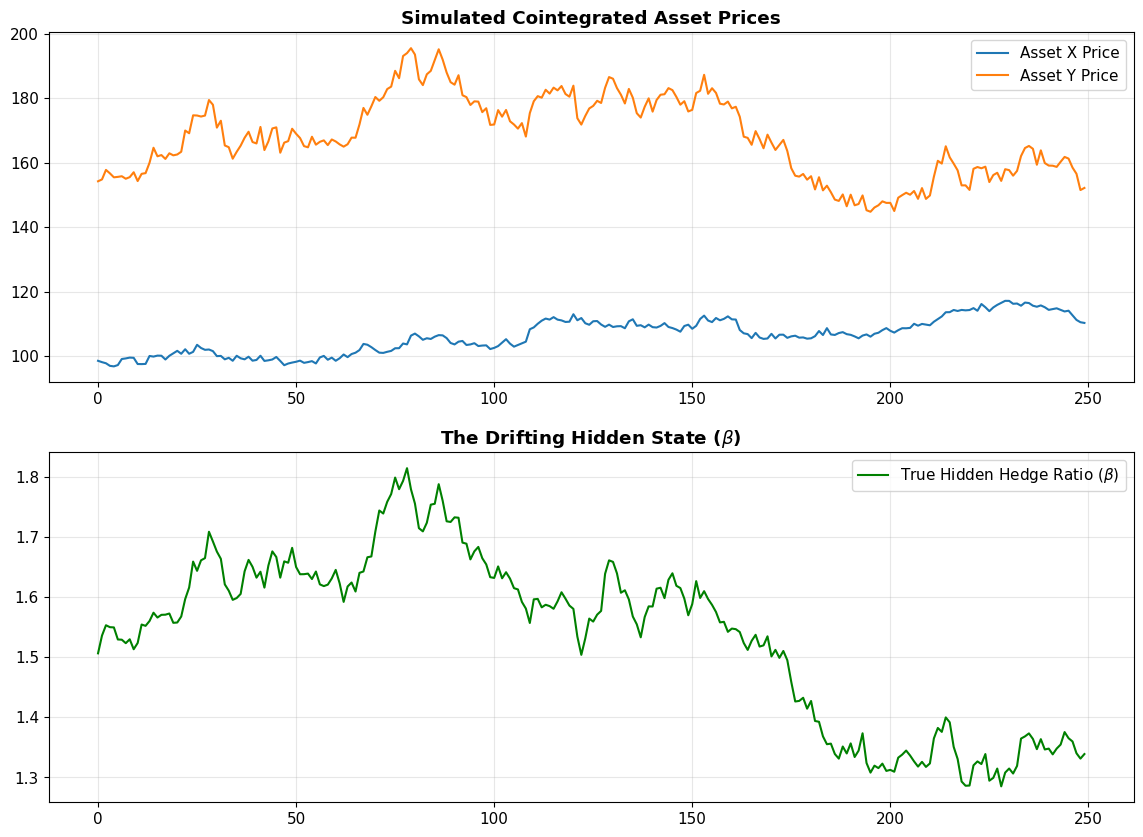

In [5]:
# Simulate Asset X (e.g., a stock price starting at 100)
n_days = 250
x_prices = np.cumsum(np.random.normal(0, 1, n_days)) + 100

# True beta represents the true, unobservable hedge ratio that wanders slowly over time
true_beta = np.cumsum(np.random.normal(0, 0.02, n_days)) + 1.5

# True alpha (intercept) is relatively stable
true_alpha = 5.0

# Simulate Asset Y based on Asset X, true beta, alpha, and some market noise
market_noise = np.random.normal(0, 1.0, n_days)
y_prices = (true_beta * x_prices) + true_alpha + market_noise

fig, axs = plt.subplots(2, 1, figsize=(14, 10))
axs[0].plot(x_prices, label='Asset X Price')
axs[0].plot(y_prices, label='Asset Y Price')
axs[0].set_title('Simulated Cointegrated Asset Prices')
axs[0].legend()

axs[1].plot(true_beta, label=r'True Hidden Hedge Ratio ($\beta$)', color='green')
axs[1].set_title(r'The Drifting Hidden State ($\beta$)')
axs[1].legend()
plt.show()

## 7. Extracting the Hedge Ratio with Kalman Filter

We assume the hidden state $\theta_k = [\beta_k, \alpha_k]^T$ evolves via a random walk. Therefore, our State Transition Matrix $F$ is just the Identity Matrix.

- $F = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$

- $H_k = \begin{bmatrix} X_k & 1 \end{bmatrix}$ *(Note: this matrix changes at every time step $k$!)*

In [6]:
# Our initial guess for beta and alpha
theta_est = np.array([[0.0], [0.0]])

# State Transition (Identity - parameters evolve as a random walk)
F = np.eye(2)

# Initial uncertainty
P = np.array([[100.0, 0.0],
              [0.0, 100.0]])

# Measurement noise - variance of Y's price noise
R = np.array([[1.0]])

# Process noise - how fast we allow the beta and alpha to drift
# We keep it very small so the filter doesn't jump wildly at every price tick
Q = np.array([[1e-4, 0.0],
              [0.0, 1e-4]])

kalman_beta_estimates = []

# To compare, we will also run a standard static linear regression (OLS)
from scipy.stats import linregress
static_beta, _, _, _, _ = linregress(x_prices, y_prices)

for k in range(n_days):
    # Observation Matrix at time k
    H = np.array([[x_prices[k], 1.0]])
    
    # Measurement at time k
    z = y_prices[k]
    
    # --- PREDICT ---
    theta_pred = F @ theta_est
    P_pred = F @ P @ F.T + Q
    
    # --- UPDATE ---
    # Residual: True Y - Predicted Y
    y_residual = z - (H @ theta_pred)[0, 0]
    
    # Innovation Covariance
    S = H @ P_pred @ H.T + R
    
    # Kalman Gain
    K = P_pred @ H.T @ np.linalg.inv(S)
    
    # Update State
    theta_est = theta_pred + K * y_residual
    
    # Update Covariance
    P = (np.eye(2) - K @ H) @ P_pred
    
    # Store dynamic beta
    kalman_beta_estimates.append(theta_est[0, 0])

kalman_beta_estimates = np.array(kalman_beta_estimates)

## 8. Dynamic Beta vs. Static Beta

Notice how the static OLS regression finds a single "average" beta for the entire time period. If we built a hedge using this static beta, we would be severely under-hedged or over-hedged for large portions of the timeline!

The **Kalman Filter** perfectly adapts to the shifting market dynamics, updating its beta estimate exactly in sync with the true hidden beta.

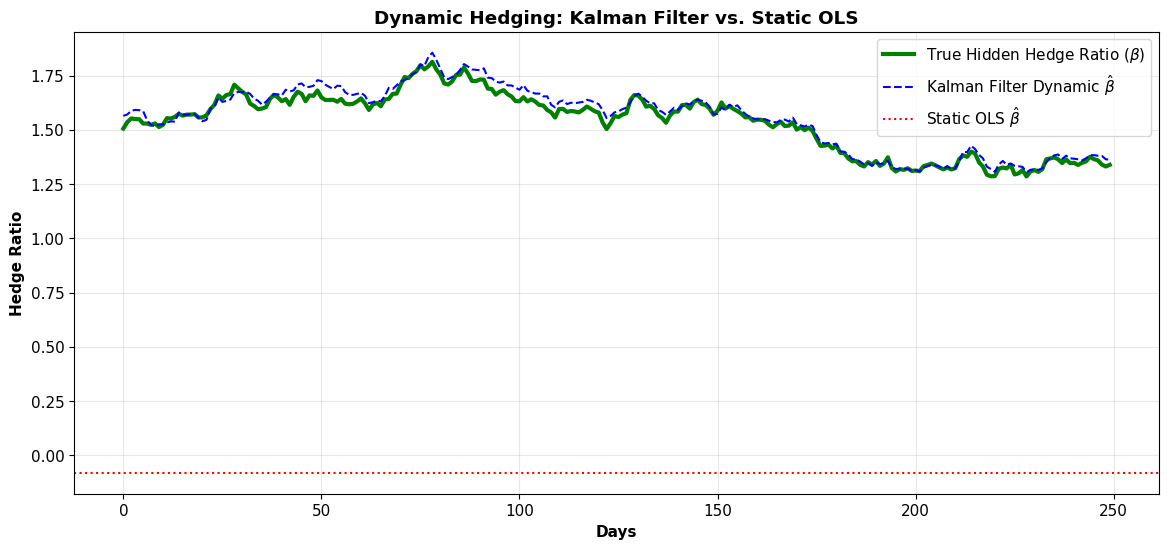

In [7]:
plt.plot(true_beta, label=r'True Hidden Hedge Ratio ($\beta$)', color='green', linewidth=3)
plt.plot(kalman_beta_estimates, label=r'Kalman Filter Dynamic $\hat{\beta}$', color='blue', linestyle='--')
plt.axhline(static_beta, label=r'Static OLS $\hat{\beta}$', color='red', linestyle=':')

plt.title('Dynamic Hedging: Kalman Filter vs. Static OLS')
plt.xlabel('Days')
plt.ylabel('Hedge Ratio')
plt.legend()
plt.show()

---
# 9. Concluding Summary

The Kalman Filter's core advantage is its dynamic, recursive nature. By balancing structural belief in how a system operates (the state-transition matrix) against live noisy data (the measurement matrix), it iteratively isolates signal from chaos.

Whether keeping the Apollo module on course, smoothing out GPS jitter on a smartphone, or dynamically adjusting position sizes in a pairs trade, it remains one of the most elegant and practical algorithms ever invented.